# 01 Průzkum dat: jak magnetická data vypadají

**Otázka.** Které vlastnosti magnetických dat úlohy IPP 1 (tokamak COMPASS, 24 magnetických měření, 31 parametrů tvaru)
rozhodují o tom, jak model učit a hodnotit? Podíváme se na strukturu dat, na chybějící cíle, na redundanci vstupů,
na nerovnoměrné rozdělení tvarů a na šum přidaný ve druhém souboru. Na malém pokusu také ukážeme, proč se data musí
dělit po celých výbojích.

Surová data jsou důvěrná. Notebook vypisuje jen souhrnné statistiky a kreslí grafy, nikdy surové řádky.

Doba běhu: pod minutu (změřeno 6 s, 2 vlákna CPU). Stačí surová data `equil_data.csv` a `equil_data_noisy.csv` (README, kapitola 3 „Spuštění“).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data: HACKATHON_HOME, jinak samotný repozitář, pokud má složku data/, jinak nadřazená složka repozitáře.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře")
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("složka se surovými daty nalezena:", C.DATA.exists(), "| složka s výsledky nalezena:", C.OUT.exists())

složka se surovými daty nalezena: True | složka s výsledky nalezena: True


## 1. Rozsah a struktura

In [2]:
df, X, Y, G, M = C.load()
x_cols = [c for c in df.columns if c.startswith(("IPR", "FL"))]
per = df.groupby("discharge").size()
srt = df.sort_values(["discharge", "time"])
step = srt.groupby("discharge").time.diff().dropna()
J = {t: i for i, t in enumerate(C.TARGETS)}
KEY = {}
KEY["rows"] = int(len(df)); KEY["columns"] = int(df.shape[1]); KEY["inputs"] = len(x_cols)
KEY["discharges"] = int(df.discharge.nunique())
KEY["rows_per_discharge"] = [int(per.min()), float(per.median()), int(per.max())]
KEY["time_range"] = [float(df.time.min()), float(df.time.max())]
KEY["median_time_step"] = float(step.median())
KEY["missing_inputs"] = int(df[x_cols].isna().sum().sum())
print(f"řádků {KEY['rows']}, sloupců {KEY['columns']}, vstupů {KEY['inputs']}, modelovaných cílů {len(C.TARGETS)}")
print(f"výbojů {KEY['discharges']}; řádků na výboj min / medián / max = {KEY['rows_per_discharge']}")
print(f"relativní čas jde od {KEY['time_range'][0]} do {KEY['time_range'][1]}; mediánový krok {KEY['median_time_step']:.4f} (zlomek výboje)")
print("chybějící hodnoty mezi 24 vstupy:", KEY["missing_inputs"])

řádků 42972, sloupců 57, vstupů 24, modelovaných cílů 16
výbojů 149; řádků na výboj min / medián / max = [17, 293.0, 439]
relativní čas jde od 0.0 do 1.0; mediánový krok 0.0030 (zlomek výboje)
chybějící hodnoty mezi 24 vstupy: 0


Jeden řádek je jeden okamžik jednoho výboje. Řádky téhož výboje jsou si téměř kopiemi, a to je důležité pro dělení dat
(oddíl 8). `time` běží v každém výboji od 0 do 1, je to tedy relativní čas. Jednotky vstupů jsou ty ze souboru (organizátoři je neuvádějí); každý model vstupy nejdřív standardizuje.

## 2. Čtyřiadvacet vstupů (jen souhrnné statistiky)

In [3]:
print(df[x_cols].describe().T[["min", "mean", "max", "std"]].round(4).to_string())

          min    mean     max     std
IPR01 -0.2662 -0.1317  0.2664  0.0974
IPR02 -0.2511 -0.1273  0.2497  0.0924
IPR03 -0.2351 -0.1158  0.2223  0.0836
IPR04 -0.1670 -0.0748  0.1464  0.0530
IPR05 -0.1260 -0.0500  0.1034  0.0351
IPR06 -0.1115 -0.0190  0.0882  0.0171
IPR07 -0.2338 -0.0789  0.1892  0.0586
IPR08 -0.3374 -0.1578  0.3298  0.1177
IPR09 -0.5651 -0.2587  0.5536  0.1978
IPR10 -0.3555 -0.1503  0.3276  0.1127
IPR11 -0.2115 -0.0747  0.1718  0.0563
IPR12 -0.1088 -0.0193  0.0856  0.0175
IPR13 -0.0739  0.0162  0.0818  0.0344
IPR14 -0.1338 -0.0558  0.1210  0.0400
IPR15 -0.2561 -0.1185  0.2399  0.0866
IPR16 -0.2926 -0.1438  0.2937  0.1065
FL01  -0.3119  0.0707  0.3345  0.1426
FL02  -0.2972  0.0482  0.3059  0.1343
FL03  -0.2944  0.0506  0.3042  0.1378
FL04  -0.2940  0.0616  0.3017  0.1433
FL05  -0.2940  0.0615  0.3019  0.1432
FL06  -0.2955  0.0504  0.2998  0.1373
FL07  -0.2987  0.0428  0.3016  0.1326
FL08  -0.3197  0.0852  0.3442  0.1482


## 3. Cíle: které kde existují a jak velký je jejich rozptyl

Některé cíle existují jen v jedné konfiguraci plazmatu. Zjistíme přesně, jak jsou chybějící hodnoty zapsané, protože
ztráta s maskou je musí přeskočit (a nesmí je brát jako nuly).

In [4]:
rows = []
for t in C.TARGETS:
    scale, unit = C.UNIT[t]
    v = Y[M[:, J[t]], J[t]] * scale
    rows.append(dict(cíl=t, jednotka=unit or "-", přítomno=M[:, J[t]].mean(), průměr=v.mean(), sm_odch=v.std(), min=v.min(), max=v.max()))
print(pd.DataFrame(rows).set_index("cíl").round(4).to_string())

lim = Y[:, J["is_limited"]] > 0.5
KEY["limited_share"] = float(lim.mean())
for t in ("R_limiter", "Z_limiter"):
    KEY[f"{t}_present_equals_limited"] = float((M[:, J[t]] == lim).mean())
for t in ("R_x_point", "Z_x_point", "R_strike_point_1", "R_strike_point_2"):
    KEY[f"{t}_present_equals_divertor"] = float((M[:, J[t]] == ~lim).mean())
KEY["rows_missing_in_always_present_targets"] = int((~M[:, J["plasma_current"]]).sum())
KEY["negative_current_share"] = float(np.nanmean(Y[:, J["plasma_current"]] < 0))
print()
print(f"řádky bez plasma_current (a elongace, triangularity): {KEY['rows_missing_in_always_present_targets']}")
print(f"podíl limiterových řádků: {lim.mean():.3f}; proud plazmatu je záporný v {KEY['negative_current_share']:.3f} řádků")
for k, v in KEY.items():
    if "present_equals" in k:
        print(f"  podíl řádků, kde '{k.split('_present')[0]}' je přítomno přesně podle očekávání: {v:.4f}")

                    jednotka  přítomno      průměr     sm_odch         min         max
cíl                                                                                   
plasma_current            kA    1.0000 -157.565002  114.184402 -318.382904  318.450195
R_mag_axis                mm    1.0000  561.100403    8.021600  462.312988  674.115417
Z_mag_axis                mm    1.0000   16.685900   13.741100 -197.908997  143.143295
elongation                 -    1.0000    1.616300    0.270600    0.886500    1.893700
triangularity              -    1.0000    0.305400    0.119400   -0.052100    0.527500
triangularity_upper        -    1.0000    0.204100    0.074900   -0.096400    0.469100
triangularity_lower        -    1.0000    0.406600    0.172400   -0.072100    0.729500
R_x_point                 mm    0.5576  463.161987    8.056300  409.965210  482.795593
Z_x_point                 mm    0.5576 -328.587402   12.736700 -357.898407 -280.186401
R_strike_point_1          mm    0.5573  433

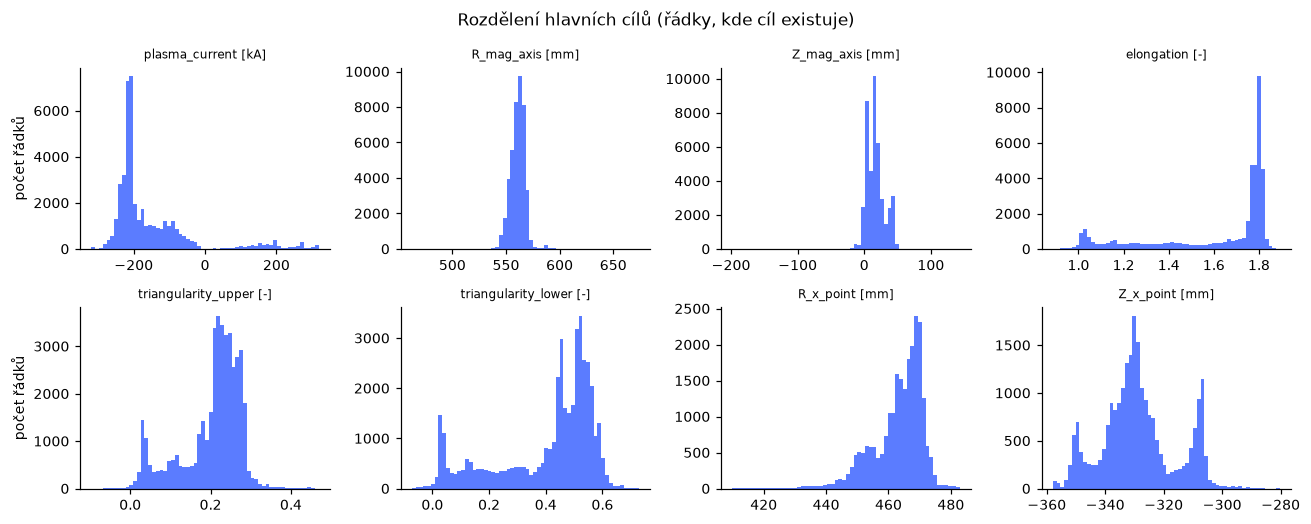

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(12, 4.8))
for a, t in zip(ax.ravel(), ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity_upper", "triangularity_lower", "R_x_point", "Z_x_point"]):
    scale, unit = C.UNIT[t]
    a.hist(Y[M[:, J[t]], J[t]] * scale, bins=60, color="#5b7cff")
    a.set_title(f"{t} [{unit or '-'}]", fontsize=8)
for a in ax[:, 0]:
    a.set_ylabel("počet řádků")
fig.suptitle("Rozdělení hlavních cílů (řádky, kde cíl existuje)")
fig.tight_layout(); plt.show()

Histogramy jsou daleko od rovnoměrných: spousta hodnot se hromadí v úzkém pásu. Oddíl 5 to vyjádří číslem.

## 4. Vstupy jsou velmi redundantní

Hlavní komponenty 24 standardizovaných vstupů ukazují, kolik rozptylu leží v několika málo směrech.

kumulativní vysvětlený rozptyl prvních 8 komponent: [0.62181 0.92779 0.98239 0.99428 0.99925 0.99958 0.99985 0.99992]
komponent potřebných pro 99,9 % rozptylu: 5


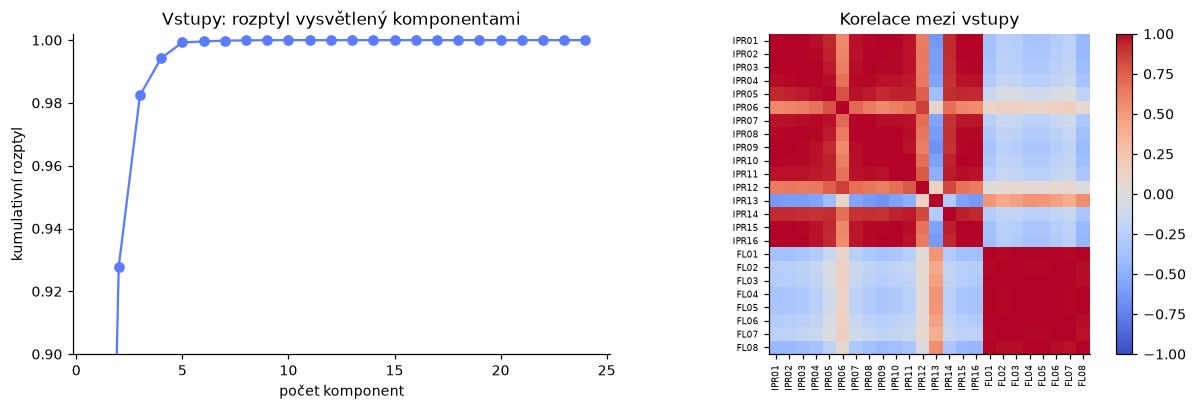

In [6]:
Z = ((X - X.mean(0)) / X.std(0)).astype(np.float64)
ev = np.linalg.svd(Z, compute_uv=False) ** 2
ev /= ev.sum()
cum = np.cumsum(ev)
KEY["pca_components_for_99_9pct"] = int(np.searchsorted(cum, 0.999) + 1)
KEY["pca_cumulative_first5"] = [round(float(v), 5) for v in cum[:5]]
print("kumulativní vysvětlený rozptyl prvních 8 komponent:", np.round(cum[:8], 5))
print("komponent potřebných pro 99,9 % rozptylu:", KEY["pca_components_for_99_9pct"])

corr = np.corrcoef(Z.T)
off = corr[np.triu_indices(24, 1)]
KEY["input_abs_corr_median"] = float(np.median(np.abs(off)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1, 25), cum, marker="o", color="#5b7cff")
ax[0].set_ylim(0.9, 1.002); ax[0].set_xlabel("počet komponent"); ax[0].set_ylabel("kumulativní rozptyl")
ax[0].set_title("Vstupy: rozptyl vysvětlený komponentami")
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(24)); ax[1].set_xticklabels(x_cols, rotation=90, fontsize=6)
ax[1].set_yticks(range(24)); ax[1].set_yticklabels(x_cols, fontsize=6)
ax[1].set_title("Korelace mezi vstupy")
fig.colorbar(im, ax=ax[1], fraction=0.046); fig.tight_layout(); plt.show()

## 5. Tvary jsou korelované a pár řádků převažuje

Elongace a triangularita leží na úzké křivce, takže data obsahují málo neobvyklých tvarů (18 výbojů s nízkou elongací se zkoumá v notebooku 07). Ukáže to graf hustoty
(2D histogram, žádné jednotlivé řádky).

rozsah elongace 0.887 až 1.894; 3 nejplnější z 40 stejně širokých košů drží 0.56 všech řádků
korelace elongace a triangularity 0.976


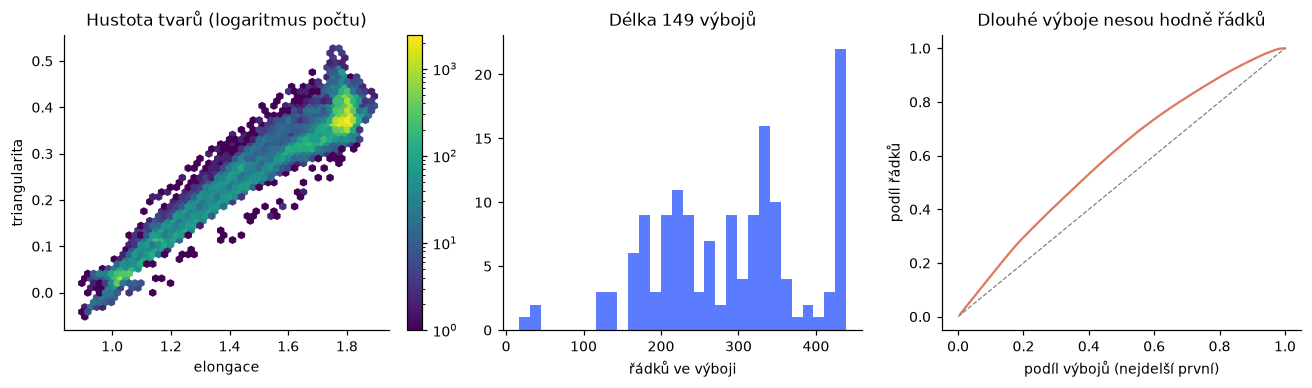

nejdelších 10 % výbojů drží 0.15 všech řádků


In [7]:
ok = M[:, J["elongation"]] & M[:, J["triangularity"]]
el, tr = Y[ok, J["elongation"]], Y[ok, J["triangularity"]]
KEY["corr_elongation_triangularity"] = float(np.corrcoef(el, tr)[0, 1])
hist, edges = np.histogram(el, bins=40)
KEY["elongation_top3_bins_of_40_share"] = float(np.sort(hist)[-3:].sum() / len(el))
KEY["elongation_range"] = [float(el.min()), float(el.max())]
print(f"rozsah elongace {el.min():.3f} až {el.max():.3f}; 3 nejplnější z 40 stejně širokých košů drží {KEY['elongation_top3_bins_of_40_share']:.2f} všech řádků")
print(f"korelace elongace a triangularity {KEY['corr_elongation_triangularity']:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
h = ax[0].hexbin(el, tr, gridsize=50, bins="log", cmap="viridis", mincnt=1)
ax[0].set_xlabel("elongace"); ax[0].set_ylabel("triangularita"); ax[0].set_title("Hustota tvarů (logaritmus počtu)")
fig.colorbar(h, ax=ax[0], fraction=0.046)
ax[1].hist(per.values, bins=30, color="#5b7cff"); ax[1].set_xlabel("řádků ve výboji"); ax[1].set_title("Délka 149 výbojů")
top = per.sort_values(ascending=False)
KEY["top10pct_discharges_row_share"] = float(top.iloc[: int(round(0.1 * len(top)))].sum() / top.sum())
ax[2].plot(np.arange(1, len(top) + 1) / len(top), np.cumsum(top.values) / top.sum(), color="#e07a5f")
ax[2].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--")
ax[2].set_xlabel("podíl výbojů (nejdelší první)"); ax[2].set_ylabel("podíl řádků"); ax[2].set_title("Dlouhé výboje nesou hodně řádků")
fig.tight_layout(); plt.show()
print(f"nejdelších 10 % výbojů drží {KEY['top10pct_discharges_row_share']:.2f} všech řádků")

## 6. Jeden výboj v čase

Kreslí se výboj s mediánovým počtem řádků; modře jsou řádky, kde se plazma dotýká limiteru.

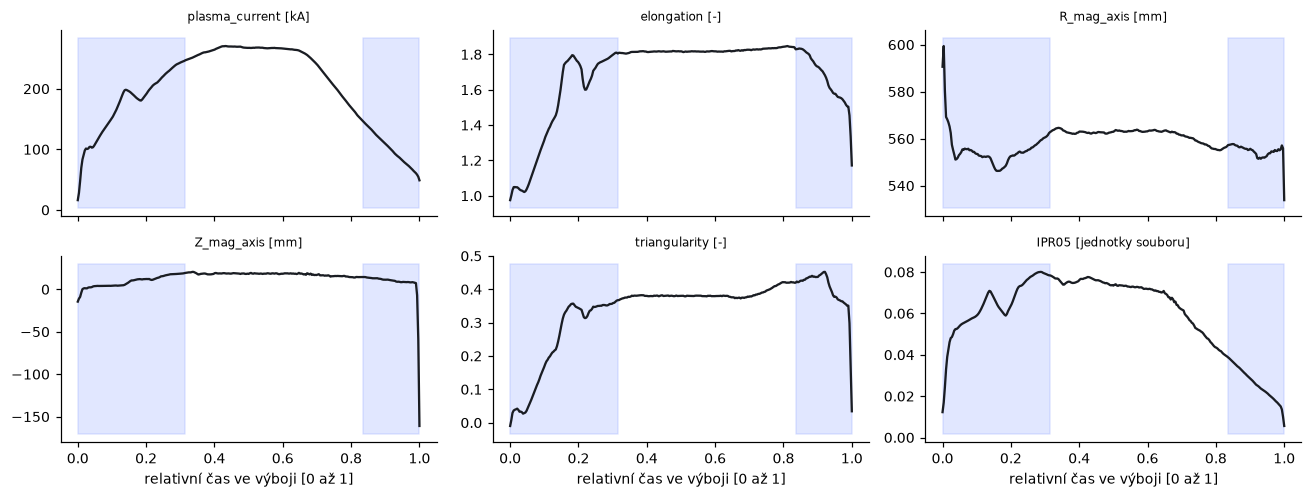

In [8]:
g = per.index[np.argsort(per.values, kind="stable")[len(per) // 2]]
d = df[df.discharge == g].sort_values("time")
fig, ax = plt.subplots(2, 3, figsize=(12, 4.6), sharex=True)
for a, c in zip(ax.ravel(), ["plasma_current", "elongation", "R_mag_axis", "Z_mag_axis", "triangularity", "IPR05"]):
    scale = C.UNIT.get(c, (1.0, ""))[0]
    a.plot(d.time, d[c] * scale, color="#1a1d23")
    lo, hi = a.get_ylim()
    a.fill_between(d.time, lo, hi, where=d.is_limited.astype(bool), color="#8aa0ff", alpha=0.25)
    a.set_title(f"{c} [{C.UNIT.get(c, (1, 'jednotky souboru'))[1] or '-'}]", fontsize=8)
for a in ax[1]:
    a.set_xlabel("relativní čas ve výboji [0 až 1]")
fig.tight_layout(); plt.show()
KEY["median_discharge_rows"] = int(len(d))

## 7. Zašuměný soubor

`equil_data_noisy.csv` má stejné řádky a stejné referenční hodnoty (štítky); mění se jen vstupy. Změříme, jak velká ta změna
je vzhledem k rozptylu každého vstupu a jestli připomíná drift v čase. Kontrola (týž šum s promíchanými řádky uvnitř každého
výboje) ukáže, co by dal čistě náhodný šum.

stejné řádky v obou souborech: True | cíle totožné: True
směr. odchylka šumu / směr. odchylka signálu na vstup (min, medián, max): [0.086 0.155 0.167]
průměr |korelace šumu s časem| uvnitř výboje: 0.050; promíchaná kontrola 0.052


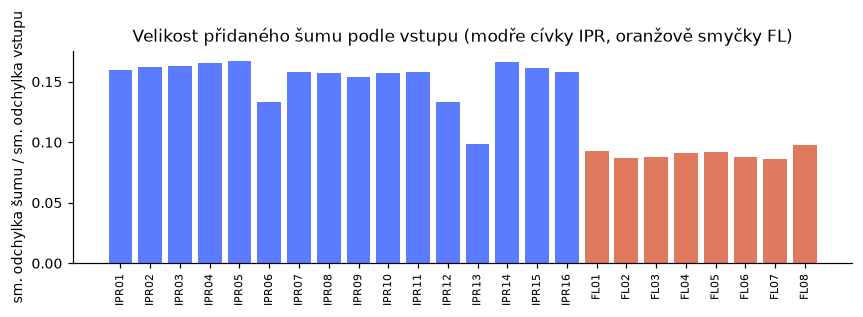

In [9]:
dn, Xn, Yn, Gn, Mn = C.load(noisy=True)
KEY["same_rows"] = bool(np.array_equal(dn.discharge.values, df.discharge.values) and np.allclose(dn.time.values, df.time.values))
KEY["targets_identical"] = bool(np.allclose(np.nan_to_num(Y, nan=-999), np.nan_to_num(Yn, nan=-999)))
noise = (Xn - X).astype(np.float64)
ratio = noise.std(0) / X.std(0)
KEY["noise_over_signal_std"] = [float(ratio.min()), float(np.median(ratio)), float(ratio.max())]
rng = np.random.default_rng(0)
t_all = df.time.values.astype(np.float64)


def mean_abs_corr_with_time(nz):
    out = []
    for idx in df.groupby("discharge").indices.values():
        if len(idx) < 6:
            continue
        tc = t_all[idx] - t_all[idx].mean()
        nc = nz[idx] - nz[idx].mean(0)
        c = (tc @ nc) / (np.sqrt((tc ** 2).sum()) * np.sqrt((nc ** 2).sum(0)) + 1e-12)
        out.append(np.abs(c).mean())
    return float(np.mean(out))


shuffled = noise.copy()
for idx in df.groupby("discharge").indices.values():
    shuffled[idx] = noise[rng.permutation(idx)]
KEY["noise_abs_corr_with_time"] = mean_abs_corr_with_time(noise)
KEY["noise_abs_corr_with_time_shuffled_control"] = mean_abs_corr_with_time(shuffled)
print("stejné řádky v obou souborech:", KEY["same_rows"], "| cíle totožné:", KEY["targets_identical"])
print("směr. odchylka šumu / směr. odchylka signálu na vstup (min, medián, max):", np.round(KEY["noise_over_signal_std"], 3))
print(f"průměr |korelace šumu s časem| uvnitř výboje: {KEY['noise_abs_corr_with_time']:.3f}; promíchaná kontrola {KEY['noise_abs_corr_with_time_shuffled_control']:.3f}")
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(24), ratio, color=["#5b7cff" if c.startswith("IPR") else "#e07a5f" for c in x_cols])
ax.set_xticks(range(24)); ax.set_xticklabels(x_cols, rotation=90, fontsize=7)
ax.set_ylabel("sm. odchylka šumu / sm. odchylka vstupu"); ax.set_title("Velikost přidaného šumu podle vstupu (modře cívky IPR, oranžově smyčky FL)")
fig.tight_layout(); plt.show()

## 8. Proč dělit po celých výbojích

Regresor 1 nejbližšího souseda na standardizovaných vstupech předpovídá `R_mag_axis`. Při náhodném dělení po řádcích má
testovací řádek skoro vždy v učicí sadě blízkou kopii sebe sama z téhož výboje. Při dělení po výbojích ne. Rozdíl ukazuje,
jak moc by dělení po řádcích zlepšilo vzhled libovolného modelu. (Všude jinde se používá GroupKFold po výbojích.)

1-NN R_mag_axis MAE: náhodné dělení po řádcích 0.617 mm, dělení po výbojích 2.027 mm


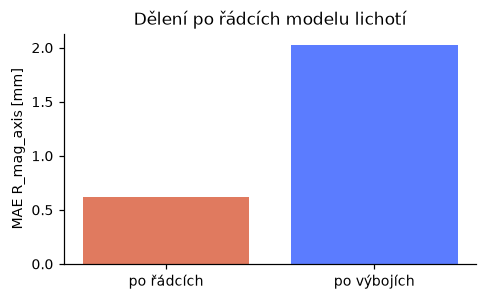

In [10]:
from sklearn.model_selection import GroupKFold, KFold
from sklearn.neighbors import KNeighborsRegressor

jr = J["R_mag_axis"]
Zs = ((X - X.mean(0)) / X.std(0)).astype(np.float32)


def knn_mae(splits):
    errs = []
    for tr_i, te_i in splits:
        m = KNeighborsRegressor(n_neighbors=1, algorithm="brute").fit(Zs[tr_i], Y[tr_i, jr])
        errs.append(np.abs(m.predict(Zs[te_i]) - Y[te_i, jr]).mean() * 1000)
    return float(np.mean(errs))


KEY["knn_mae_mm_row_split"] = knn_mae(KFold(5, shuffle=True, random_state=0).split(Zs))
KEY["knn_mae_mm_discharge_split"] = knn_mae(GroupKFold(5).split(Zs, groups=G))
print(f"1-NN R_mag_axis MAE: náhodné dělení po řádcích {KEY['knn_mae_mm_row_split']:.3f} mm, dělení po výbojích {KEY['knn_mae_mm_discharge_split']:.3f} mm")
fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.bar(["po řádcích", "po výbojích"], [KEY["knn_mae_mm_row_split"], KEY["knn_mae_mm_discharge_split"]], color=["#e07a5f", "#5b7cff"])
ax.set_ylabel("MAE R_mag_axis [mm]"); ax.set_title("Dělení po řádcích modelu lichotí")
fig.tight_layout(); plt.show()

## Závěry

- **Rozsah.** 42 972 řádků ze 149 výbojů (17 až 439 řádků na výboj, medián 293), 24 vstupů bez jediné chybějící hodnoty a `time` je relativní čas od 0 do 1. Skutečný čas mezi dvěma řádky v souboru není (`time` je relativní), takže nic v tomto repozitáři netvrdí nic o milisekundách na řádek (otevřená otázka pro organizátory).
- **Chybějící cíle jsou strukturální, ztráta proto musí mít masku.** `R_x_point` a `Z_x_point` existují přesně v divertorových řádcích, `R_limiter` a `Z_limiter` přesně v limiterových (44,2 % všech řádků je limiterových). Dotykové body sledují divertorovou konfiguraci ve všech řádcích kromě 11. Jednomu řádku chybí `plasma_current`, `elongation` a triangularity. Proud plazmatu je záporný v 92,6 % řádků, takže se musí zachovat jeho znaménko. `Z_x_point` leží v každém divertorovém řádku mezi -358 a -280 mm, X bod je tedy vždy dolní (dolní jednoduchý nulový bod); data neobsahují horní X bod ani dvojitý nulový bod, takže o nich nic nevíme.
- **Vstupy jsou redundantní v rozptylu.** Prvních 5 hlavních komponent 24 vstupů obsahuje 99,93 % rozptylu (99,9 % dosáhnou už 5 komponent) a medián absolutní korelace dvou vstupů je 0,57. To ale neznamená redundantní informaci: síť, která vidí jen těchto 5 komponent, má chybu radiální osy 2,63 mm proti 0,41 mm při všech 24 vstupech (stejné foldy a semínko, `results/data-checks.md`). Méně senzorů zkoušíme přímo v notebooku 03.
- **Tvary jsou nerovnoměrné a silně korelované.** Elongace jde od 0,89 do 1,89 (hodnoty pod 1 jsou pro tokamakové plazma neobvyklé a vzorec organizátorů tu nemáme zaznamenaný, takže ty řádky neinterpretujeme; ověřit s ústavem), její korelace s triangularitou je 0,976 a 3 nejplnější z 40 stejně širokých košů drží 56 % řádků. Nejdelších 10 % výbojů drží 15 % řádků, takže dlouhé výboje váží při učení i hodnocení víc (chyba na vzácných tvarech je v notebooku 02).
- **Rozptyl je malý jen u osy, X bodu a dotykových bodů** (směrodatná odchylka 2,4 až 13,7 mm); bod limiteru má 90 mm (R) a 153 mm (Z) a proud plazmatu 114 kA, proto se chyby uvádějí ve fyzikálních jednotkách a vedle rozptylu každého cíle.
- **Zašuměný soubor** má stejné řádky a totožné referenční hodnoty. Směrodatná odchylka přidaného šumu je 8,6 % až 16,7 % směrodatné odchylky každého vstupu (medián 15,5 %; zhruba 9 % u smyček toku a 16 % u cívek). Šum je bílý (autokorelace o jeden krok -0,004, `results/data-checks.md`) a nemá měřitelný drift: jeho průměrná absolutní korelace s časem uvnitř výboje je 0,050, stejně jako u promíchané kontroly (0,052). Úzké rozmezí poměru naznačuje, že se šum přidával úměrně každému vstupu (náš závěr, nepotvrzený) a může být větší než šum skutečných sond (ověřit s ústavem), takže chyby na tomto souboru jsou zátěžový test, ne očekávaná přesnost v provozu. Každý výsledek o driftu v notebooku 08 používá drift, který jsme si vygenerovali sami.
- **Dělení po celých výbojích je nutné.** Model nejbližšího souseda má chybu `R_mag_axis` 0,62 mm při náhodném dělení po řádcích a 2,03 mm při dělení po výbojích, tedy 3,3krát víc. Dělení po řádcích by tomuto modelu přidalo zhruba trojnásobně lepší vzhled a jiné modely to pravděpodobně zkreslí také. Náhodné skupinové foldy jsou pro pozdější kampaň stále optimistické: čísla výbojů zřejmě sledují čas (organizátoři nepotvrdili) a na výbojích s vyššími čísly je chyba větší (notebooky 08 a 09).

*Závěry výše jsem opsal z výstupů uloženého běhu; po novém spuštění se mírně liší.*

**Odpověď.** Dělit po celých výbojích (dělení po řádcích zlepší vzhled modelu nejbližšího souseda zhruba 3,3krát), maskovat cíle, které neexistují (chybí právě v druhé konfiguraci), uvádět chyby v mm a kA vedle rozptylu každého cíle a redundanci vstupů brát jen jako redundanci v rozptylu: 5 komponent drží 99,93 % rozptylu, a přesto má síť na nich chybu radiální osy 2,63 mm proti 0,41 mm. Dodaný zašuměný soubor je bílý šum bez měřitelného driftu.